# Synthetic SSNAP data for demonstrating the S-learner code

## Summary

**Aim.** To build a synthetic version of the cleaned SSNAP data that can be shared and used to demonstrate the S-learner's machine learning code, with outcomes related to patient characteristics and treatment as in the real data.

**Data.** All 452,863 records in the cleaned SSNAP data (2020–2025), with 27 fields in the order of the patient pathway: team and patient characteristics, stroke onset, arrival, assessment and imaging, treatment (including transfer for thrombectomy) and outcome (discharge mRS, death, length of stay). No patients are selected or excluded.

**Method.** Sequential synthesis along the pathway: stroke team is sampled from the real team sizes, then each field is generated from a gradient-boosted classification model fitted to the real data, given all the fields generated before it. Times are generated as steps along the pathway, so events stay in order. The outcomes (discharge mRS and length of stay) are modelled separately for each treatment received, with the total onset-to-treatment times as predictors, so that the effects of treatment and time to treatment are reproduced. Death is set from discharge mRS. Stroke teams have anonymous names (synth001 to synth116), the models need at least 100 patients per leaf, and extreme times are not reproduced.

**Main results.**

* The synthetic data has 452,863 records with the same 27 columns, names, order and types as the real data, and breaks none of the pathway rules.
* Distributions match closely: means and SDs of patient characteristics within 0.01, ethnicity and discharge mRS percentages within 0.2 percentage points, and median times within 8 minutes (median length of stay 7 days in both).
* Relationships are preserved: rank correlations differ by at most 0.08, and a logistic regression of good outcome on 15 characteristics gives coefficients within 0.031 of the real ones.
* The effect of time to treatment is reproduced: after thrombolysis only, good outcome falls from 60.2% (real 62.8%) within 90 minutes to 53.0% (54.0%) after 6 hours; after thrombectomy only, from 43.1% (44.5%) within 3 hours to 25.6% (28.7%) after 12 hours.
* A model trained on synthetic data predicts good outcome in real data as well as a model trained on real data (ROC AUC 0.797 for both).
* The S-learner's cohort selection gives 72,962 synthetic patients (74,678 real), with good-outcome rates within 1.6 percentage points of the real ones for most treatment groups; thrombolysis is slightly less common (11.4% vs 12.0% of all records).
* Synthetic records match real records no more often than unseen real patients do (on the S-learner's fields, 16.1% vs 16.3%; for unique real records, 9.9% vs 9.9%).

**Conclusion.** The synthetic data reproduces the real data closely enough to demonstrate and test the S-learner code, including its cohort selection and the relationships of outcome to severity, treatment and time to treatment. It is intended for demonstration, not for estimating treatment effects.

## Method overview

**Purpose.** The real SSNAP data cannot be shared. This notebook builds a synthetic data set with the same columns as the real (cleaned) data, so that the S-learner's machine learning code can be run and demonstrated without access to patient data. The synthetic data should reproduce the distributions of the fields and, importantly, how the outcome relates to patient characteristics and treatments, while containing no real patients.

**Fields (27), in the order of the patient pathway.**

| Stage | Fields |
|---|---|
| Team and patient | stroke team, age, male, ethnicity, pre-stroke mRS, congestive heart failure, hypertension, diabetes, any AF diagnosis, AF anticoagulant |
| Stroke onset | onset known, precise onset known, onset during sleep |
| Arrival | arrive by ambulance, onset-to-arrival time |
| Assessment and imaging | NIHSS, arrival-to-scan time, stroke type (infarction), LVO, perfusion imaging |
| Treatment | onset-to-thrombolysis time, transfer used, transfer time, onset-to-thrombectomy time |
| Outcome | discharge mRS, death, length of stay |

These include all the S-learner's model features and its outcome, and the fields it uses to select its cohort. Column names and types are the same as in the real data. **All records are used: no patients are selected or excluded.**

**Approach: sequential synthesis along the pathway.** Variables are generated one at a time, in the order above. Stroke team is sampled from the real team sizes; every later variable is drawn from the predicted class probabilities of a model fitted to the real data, given all the variables already generated. Because discharge mRS and length of stay are generated after every characteristic, time and treatment, the synthetic outcomes depend on severity, age, pre-stroke disability, treatment and time to treatment in the same way as the real outcomes.

* **Outcome models:** discharge mRS and length of stay are modelled separately for each treatment received (none, thrombolysis only, thrombectomy only, both), so that the models for treated patients learn only from those patients. Their predictors also include the total onset-to-thrombolysis and onset-to-thrombectomy times, built from the pathway steps, because tree models cannot easily add the separate steps together. Without these two features the effect of time to thrombectomy was much weaker in the synthetic data than in the real data.

* **Models:** gradient-boosted classification trees (scikit-learn `HistGradientBoostingClassifier`), with missing values as their own class (for example, unrecorded LVO or discharge mRS).
* **Times** are generated as one of up to 40 quantile bins, then a whole-number value drawn uniformly within the bin. They are generated as steps along the pathway so that events stay in order: onset → arrival → scan → thrombolysis, and arrival → transfer (if transferred) → thrombectomy.
* **Pathway rules:** onset-to-arrival time and treatment are generated only when onset is known; precise onset only when onset is known; transfer time only when transferred; each treatment time only when that treatment is given; death is 1 if discharge mRS is 6, 0 if discharge mRS is 0–5, and missing if discharge mRS is missing.

**Privacy safeguards.**

* Stroke teams are given anonymous names (synth001 to synth116) in a random order.
* Each generating model needs at least 100 patients in every leaf, so rare combinations of characteristics are not learned. (A minimum of 200 weakened the effect of time to thrombolysis; 100 reproduces it, and the privacy check is unchanged.)
* The most extreme times and lengths of stay (above the 99.9th percentile) are not reproduced.
* Each synthetic record is a new random draw, not a copy or perturbation of a real record. The privacy check (section 7) tests how often synthetic records coincide with real ones, compared with how often unseen real patients do.

### Notebook structure

1. Set-up
2. Load the real data
3. Prepare the real data for the generating models
4. Generate the synthetic data
5. Convert to the real data's format, and check pathway consistency
6. Fidelity checks: distributions, correlations, outcome model, outcome by severity, treatment and time, machine learning utility, S-learner cohort
7. Privacy check
8. Save the synthetic data
9. Using the synthetic data, and conclusions

## 1. Set-up

Libraries and settings. Paths are relative to this notebook (in the `data/sam3` folder, next to the cleaned data). `N_SYNTHETIC` sets the number of synthetic records (by default the same as the real data). `MODEL_PARAMS` sets the generating models; the minimum leaf size of 100 patients is the main privacy safeguard in the models.

In [1]:
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# ---------- Settings ----------
DATA_PATH = "./cleaned_data.csv"            # real (cleaned) SSNAP data
OUTPUT_DIR = "./synthetic_data"
OUTPUT_PATH = f"{OUTPUT_DIR}/synthetic_cleaned_data.csv"
SEED = 42
N_SYNTHETIC = None        # number of synthetic records; None = same number as the real data
N_TIME_BINS = 40          # quantile bins used to generate continuous times
TAIL_QUANTILE = 0.999     # upper edge of the last time bin: the most extreme real times are not reproduced
# Generating models: gradient-boosted trees with at least 100 patients per leaf, so that
# rare combinations of characteristics (which could identify a patient) are not learned
MODEL_PARAMS = dict(max_iter=100, learning_rate=0.1, max_leaf_nodes=31,
                    min_samples_leaf=100, l2_regularization=1.0, random_state=SEED)

os.makedirs(OUTPUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

## 2. Load the real data

The cleaned SSNAP data, keeping the 27 fields in pathway order. Every record is kept. The table shows each field's type, missing values, number of distinct values and whether the S-learner uses it as a model feature or outcome.

In [2]:
# Fields in the order of the patient pathway: team and patient characteristics, stroke onset,
# arrival, assessment and imaging, treatment (including transfer for thrombectomy), and outcome
FIELDS = [
    "stroke_team", "age", "male", "ethnicity",
    "prior_disability", "congestive_heart_failure", "hypertension", "diabetes",
    "any_afib_diagnosis", "afib_anticoagulant",
    "onset_known", "precise_onset_known", "onset_during_sleep",
    "arrive_by_ambulance", "onset_to_arrival_time",
    "stroke_severity", "arrival_to_scan_time", "infarction", "lvo", "perfusion_imaging_used",
    "onset_to_thrombolysis_time", "transfer_used", "transfer_time", "onset_to_thrombectomy_time",
    "discharge_disability", "death", "length_of_stay",
]
# Fields used by the S-learner as model features or outcome (the others describe the pathway,
# are used to select the S-learner's cohort, or are additional outcomes)
S_LEARNER_FIELDS = ["prior_disability", "stroke_severity", "age", "congestive_heart_failure", "hypertension",
                    "diabetes", "afib_anticoagulant", "any_afib_diagnosis", "stroke_team", "ethnicity",
                    "onset_to_thrombolysis_time", "onset_to_thrombectomy_time", "discharge_disability"]

# All records are kept: no patients are selected or excluded
real = pd.read_csv(DATA_PATH, usecols=FIELDS, low_memory=False)[FIELDS]
print(f"Real data: {len(real):,} records, {real.shape[1]} fields")
pd.DataFrame({"type": real.dtypes.astype(str), "missing": real.isna().sum(),
              "distinct values": real.nunique(), "used by S-learner": [f in S_LEARNER_FIELDS for f in FIELDS]})

Real data: 452,863 records, 27 fields


,type,missing,distinct values,used by S-learner
stroke_team,str,0,116,True
age,float64,0,12,True
male,float64,41,2,False
ethnicity,str,0,5,True
prior_disability,int64,0,6,True
congestive_heart_failure,float64,0,2,True
hypertension,float64,0,2,True
diabetes,float64,0,2,True
any_afib_diagnosis,float64,0,2,True
afib_anticoagulant,float64,0,2,True


**Results.** 452,863 records and 27 fields, 13 of them used by the S-learner as model features or outcome. Missing values are frequent in some fields: onset-to-arrival time (128,662 records, onset unknown), LVO (368,297, not recorded), transfer time (443,234, not transferred), and the two treatment times (not given). Discharge mRS is missing for 14,274 records, death for 7,671, length of stay for 6,552 and NIHSS for 3,268.

## 3. Prepare the real data for the generating models

* Stroke teams are given anonymous codes in a random order, and ethnicity is coded as integers.
* Treatment received is coded as none, thrombolysis only, thrombectomy only or both, from whether each onset-to-treatment time is recorded.
* Times are re-expressed as steps along the pathway: scan-to-thrombolysis time (arrival-to-thrombolysis minus arrival-to-scan), and time to thrombectomy from arrival, or from transfer for transferred patients. Negative steps and negative transfer times are set to zero.

The tables show the rules that the synthetic data must respect, in the real data.

In [3]:
# Encode the real data for the generating models
work = real.copy()

# Anonymous stroke team codes: teams are numbered in a random order
teams = rng.permutation(sorted(work["stroke_team"].unique()))
team_code = {team: i for i, team in enumerate(teams)}
work["team_code"] = work["stroke_team"].map(team_code)
ethnicity_levels = sorted(work["ethnicity"].unique())
work["ethnicity_code"] = work["ethnicity"].map({e: i for i, e in enumerate(ethnicity_levels)})

# Treatment: 0 none, 1 thrombolysis only, 2 thrombectomy only, 3 both
has_ivt = work["onset_to_thrombolysis_time"].notna()
has_mt = work["onset_to_thrombectomy_time"].notna()
work["treatment"] = np.select([has_ivt & has_mt, has_ivt, has_mt], [3, 1, 2], 0)

# Times are generated as steps along the pathway, so that events stay in order:
#   arrival -> scan -> thrombolysis (scan-to-thrombolysis time)
#   arrival -> transfer (if transferred) -> thrombectomy (time after arrival, or after transfer)
arrival_to_ivt = work["onset_to_thrombolysis_time"] - work["onset_to_arrival_time"]
arrival_to_mt = work["onset_to_thrombectomy_time"] - work["onset_to_arrival_time"]
work["transfer_time_clipped"] = work["transfer_time"].clip(lower=0)
work["scan_to_thrombolysis"] = (arrival_to_ivt - work["arrival_to_scan_time"]).clip(lower=0)
work["previous_step_to_thrombectomy"] = (
    arrival_to_mt - np.where(work["transfer_used"] == 1, work["transfer_time_clipped"], 0)).clip(lower=0)

print("Onset known, onset-to-arrival time and treatment (real data):")
display(pd.crosstab([work["onset_known"], work["onset_to_arrival_time"].notna().rename("arrival time known")],
                    work["treatment"].map({0: "none", 1: "IVT only", 2: "MT only", 3: "both"})))
print("Precise onset known and onset during sleep, by onset known (real data):")
display(pd.crosstab(work["onset_known"], [work["precise_onset_known"], work["onset_during_sleep"]]))
print("Transfer and thrombectomy (real data):")
display(pd.crosstab(work["transfer_used"], work["onset_to_thrombectomy_time"].notna().rename("thrombectomy")))
print("Death and discharge mRS (real data):")
pd.crosstab(work["death"].fillna(-1).rename("death (-1 = missing)"),
            work["discharge_disability"].fillna(-1).rename("discharge mRS (-1 = missing)"))

Onset known, onset-to-arrival time and treatment (real data):


,treatment,IVT only,MT only,both,none
onset_known,arrival time known,,,,
0,False,0,0,0,128662
1,True,46509,6690,7668,263334


Precise onset known and onset during sleep, by onset known (real data):


precise_onset_known       0              1   
onset_during_sleep        0      1       0  1
onset_known                                  
0                    100449  28213       0  0
1                    140463  30812  152917  9

Transfer and thrombectomy (real data):


thrombectomy,False,True
transfer_used,,
0,435951,7283
1,2554,7075


Death and discharge mRS (real data):


discharge mRS (-1 = missing),-1.0,0.0,1.0,2.0,3.0,4.0,5.0,6.0
death (-1 = missing),,,,,,,,
-1.0,7671,0,0,0,0,0,0,0
0.0,6603,42595,83385,84716,86080,71464,27909,0
1.0,0,0,0,0,0,0,0,42440


**Results.**

* **Onset:** onset is unknown for 128,662 records, and these are exactly the records with no onset-to-arrival time; all are untreated, because onset-to-treatment times cannot be calculated without a known onset. Precise onset is known only when onset is known (152,926 records). Onset during sleep occurs whether or not onset is known.
* **Treatment:** of the 324,201 records with known onset, 46,509 received thrombolysis only, 6,690 thrombectomy only and 7,668 both.
* **Transfer:** 9,629 patients were transferred, 7,075 of whom had thrombectomy; 7,283 had thrombectomy without transfer.
* **Death:** death is 1 for exactly the 42,440 records with discharge mRS 6. Where discharge mRS is missing, death is 0 for 6,603 records and missing for 7,671; the synthetic data sets death to missing for all records with missing discharge mRS.

### Time bins

Quantile bin edges for each time and for length of stay. The top edge of each set is the 99.9th percentile rather than the maximum, so the most extreme real values are not reproduced. Values with many ties have fewer than 40 distinct bins.

In [4]:
def make_bins(values, n_bins=N_TIME_BINS, tail=TAIL_QUANTILE):
    """Quantile bin edges for a continuous time; the top edge is the tail quantile, not the maximum."""
    v = values.dropna().to_numpy()
    edges = np.unique(np.quantile(v, np.linspace(0, 1, n_bins + 1)))
    edges[-1] = np.quantile(v, tail)
    return np.unique(edges)


def to_bin(values, edges):
    """Bin index for each value (NaN stays NaN); values above the top edge go in the last bin."""
    values = np.asarray(values, dtype=float)
    bins = np.clip(np.searchsorted(edges, values, side="right") - 1, 0, len(edges) - 2).astype(float)
    bins[np.isnan(values)] = np.nan
    return bins


def from_bin(bins, edges, rng):
    """A whole-number value drawn uniformly within each bin (NaN stays NaN)."""
    bins = np.asarray(bins, dtype=float)
    out = np.full(len(bins), np.nan)
    ok = ~np.isnan(bins)
    b = bins[ok].astype(int)
    out[ok] = np.round(edges[b] + rng.random(ok.sum()) * (edges[b + 1] - edges[b]))
    return out


# (generated variable, source column in the real data)
BINNED = {
    "arrival_bin": "onset_to_arrival_time",
    "scan_bin": "arrival_to_scan_time",
    "ivt_bin": "scan_to_thrombolysis",
    "transfer_bin": "transfer_time_clipped",
    "mt_bin": "previous_step_to_thrombectomy",
    "los_bin": "length_of_stay",
}
edges = {}
for name, column in BINNED.items():
    edges[name] = make_bins(work[column])
    work[name] = to_bin(work[column], edges[name])
    print(f"{column}: {len(edges[name]) - 1} bins, {edges[name][0]:.0f} to {edges[name][-1]:.0f}")

onset_to_arrival_time: 40 bins, 1 to 28843
arrival_to_scan_time: 39 bins, 0 to 11126
scan_to_thrombolysis: 40 bins, 0 to 318
transfer_time_clipped: 40 bins, 0 to 3340
previous_step_to_thrombectomy: 40 bins, 0 to 2198
length_of_stay: 27 bins, 0 to 230


**Results.** Onset-to-arrival time is generated in 40 bins from 1 to 28,843 minutes, arrival-to-scan time in 39 bins from 0 to 11,126 minutes, scan-to-thrombolysis time in 40 bins from 0 to 318 minutes, transfer time in 40 bins from 0 to 3,340 minutes, time to thrombectomy (from arrival or transfer) in 40 bins from 0 to 2,198 minutes, and length of stay in 27 bins from 0 to 230 days.

## 4. Generate the synthetic data

Stroke team is sampled from the real team sizes. Each later variable is then modelled on the real data from all the variables before it, and generated for the synthetic records by sampling from the model's predicted class probabilities. Variables that only apply to some patients (precise onset, onset-to-arrival time, treatment, treatment and transfer times) are modelled and generated only for those patients. A value is drawn within each generated time bin straight away, so that the total onset-to-treatment times can be used as predictors for the outcomes, which are modelled separately for each treatment received. The table shows, for each variable, the number of predictors, the number of real records modelled, the number of classes and the fitting time.

In [5]:
# Variables in the order they are generated (the order of the patient pathway);
# each is predicted from all the variables before it
ORDER = [
    "team_code", "age", "male", "ethnicity_code",
    "prior_disability", "congestive_heart_failure", "hypertension", "diabetes",
    "any_afib_diagnosis", "afib_anticoagulant",
    "onset_known", "precise_onset_known", "onset_during_sleep",
    "arrive_by_ambulance", "arrival_bin",
    "stroke_severity", "scan_bin", "infarction", "lvo", "perfusion_imaging_used",
    "treatment", "ivt_bin", "transfer_used", "transfer_bin", "mt_bin",
    "discharge_disability", "los_bin",
]
CATEGORICAL = {"team_code", "ethnicity_code"}
MISSING = -1   # class label used for a missing value

# Records for which each variable is modelled and generated; other records get the default value
SUBSETS = {
    "precise_onset_known": lambda d: d["onset_known"] == 1,
    "arrival_bin": lambda d: d["onset_known"] == 1,          # onset-to-arrival time needs a known onset
    "treatment": lambda d: d["onset_known"] == 1,            # onset-to-treatment times need a known onset
    "ivt_bin": lambda d: d["treatment"].isin([1, 3]),
    "transfer_bin": lambda d: d["transfer_used"] == 1,
    "mt_bin": lambda d: d["treatment"].isin([2, 3]),
}
DEFAULT = {"precise_onset_known": 0, "treatment": 0}   # value outside the subset (otherwise missing)

# Outcomes are modelled separately for each treatment received (none, thrombolysis only, thrombectomy only,
# both), so that the models for treated patients learn only from those patients. Their predictors also
# include the total onset-to-thrombolysis and onset-to-thrombectomy times, built from the pathway steps,
# because tree models cannot easily add the separate steps together.
OUTCOMES = {"discharge_disability", "los_bin"}
TOTAL_TIMES = ["onset_to_ivt_total", "onset_to_mt_total"]
work["onset_to_ivt_total"] = work["onset_to_thrombolysis_time"]
work["onset_to_mt_total"] = work["onset_to_thrombectomy_time"]


def sample_classes(proba, classes, rng):
    """Draw one class per row from predicted class probabilities."""
    u = rng.random(len(proba))[:, None]
    idx = (proba.cumsum(axis=1) < u).sum(axis=1)
    return classes[np.minimum(idx, len(classes) - 1)]


n_synth = len(work) if N_SYNTHETIC is None else N_SYNTHETIC
synth = pd.DataFrame(index=range(n_synth))

# First variable (stroke team): sampled from the real team sizes
team_share = work["team_code"].value_counts(normalize=True).sort_index()
synth["team_code"] = rng.choice(team_share.index.to_numpy(), size=n_synth, p=team_share.to_numpy())

step_values = {}   # generated times (minutes or days), drawn within each generated bin
fit_log = []
for k, target in enumerate(ORDER[1:], start=1):
    start = time.time()
    predictors = ORDER[:k] + (TOTAL_TIMES if target in OUTCOMES else [])
    subset = SUBSETS.get(target)
    fit_rows = subset(work) if subset is not None else pd.Series(True, index=work.index)
    gen_rows = subset(synth) if subset is not None else pd.Series(True, index=synth.index)
    if target in OUTCOMES:
        groups = [(fit_rows & (work["treatment"] == t), gen_rows & (synth["treatment"] == t), t) for t in range(4)]
    else:
        groups = [(fit_rows, gen_rows, "all")]

    values = np.full(n_synth, DEFAULT.get(target, np.nan), dtype=float)
    for fit_group, gen_group, group_label in groups:
        # Class labels as text, so that non-integer values (e.g. age 37.5) are kept exactly
        y = work.loc[fit_group, target].fillna(MISSING).astype(float).astype(str)
        model = HistGradientBoostingClassifier(categorical_features=[p in CATEGORICAL for p in predictors],
                                               **MODEL_PARAMS)
        model.fit(work.loc[fit_group, predictors], y)
        if gen_group.any():
            proba = model.predict_proba(synth.loc[gen_group, predictors])
            values[gen_group.to_numpy()] = sample_classes(proba, model.classes_, rng).astype(float)
        fit_log.append({"variable": target, "treatment group": group_label, "predictors": len(predictors),
                        "records modelled": int(fit_group.sum()), "classes": len(model.classes_)})
    values[values == MISSING] = np.nan
    synth[target] = values

    # Draw a value within each generated time bin, and build the total onset-to-treatment times
    if target in BINNED:
        step_values[target] = from_bin(values, edges[target], rng)
    if target == "mt_bin":
        arrival = np.maximum(step_values["arrival_bin"], 1)
        synth["onset_to_ivt_total"] = arrival + step_values["scan_bin"] + step_values["ivt_bin"]
        synth["onset_to_mt_total"] = (arrival + np.where(synth["transfer_used"] == 1, step_values["transfer_bin"], 0)
                                      + step_values["mt_bin"])
    print(f"{target}: {time.time() - start:.1f} s")

pd.DataFrame(fit_log)

age: 2.8 s
male: 0.8 s
ethnicity_code: 1.8 s
prior_disability: 2.2 s
congestive_heart_failure: 0.9 s
hypertension: 0.9 s
diabetes: 0.9 s
any_afib_diagnosis: 0.9 s
afib_anticoagulant: 0.9 s
onset_known: 1.0 s
precise_onset_known: 0.7 s
onset_during_sleep: 1.1 s
arrive_by_ambulance: 1.5 s
arrival_bin: 8.1 s
stroke_severity: 13.0 s
scan_bin: 18.8 s
infarction: 1.4 s
lvo: 3.0 s
perfusion_imaging_used: 1.1 s
treatment: 3.4 s
ivt_bin: 2.8 s
transfer_used: 2.0 s
transfer_bin: 9.4 s
mt_bin: 1.6 s
discharge_disability: 14.7 s
los_bin: 36.2 s


,variable,treatment group,predictors,records modelled,classes
0,age,all,1,452863,12
1,male,all,2,452863,3
2,ethnicity_code,all,3,452863,5
3,prior_disability,all,4,452863,6
4,congestive_heart_failure,all,5,452863,2
5,hypertension,all,6,452863,2
6,diabetes,all,7,452863,2
7,any_afib_diagnosis,all,8,452863,2
8,afib_anticoagulant,all,9,452863,2
9,onset_known,all,10,452863,2


**Results.** Thirty-two models were fitted, taking a few minutes in total. Onset-to-arrival time and treatment were modelled on the 324,201 records with a known onset, scan-to-thrombolysis time on 54,177 thrombolysed records, transfer time on 9,629 transferred records and time to thrombectomy on 14,358 thrombectomy records. Discharge mRS and length of stay were each modelled in four treatment groups: no treatment (391,996 records, including all with unknown onset), thrombolysis only (46,509), thrombectomy only (6,690) and both (7,668).

## 5. Convert to the real data's format

Codes are converted back to the real columns: anonymous team names (synth001 to synth116), ethnicity labels, and the times (whole minutes) and length of stay (whole days) drawn during synthesis. Onset-to-treatment times are built from the pathway steps (onset-to-thrombolysis = onset-to-arrival + arrival-to-scan + scan-to-thrombolysis; onset-to-thrombectomy = onset-to-arrival + transfer time, if transferred, + time to thrombectomy), and death is set from discharge mRS. The synthetic data has exactly the same column names, order and types as the real data.

In [6]:
# Convert the generated codes back to the real data's columns and formats
synthetic = pd.DataFrame(index=synth.index)
synthetic["stroke_team"] = synth["team_code"].astype(int).map(lambda i: f"synth{i + 1:03d}")   # anonymous names
synthetic["ethnicity"] = synth["ethnicity_code"].astype(int).map(dict(enumerate(ethnicity_levels)))
for col in ["age", "male", "prior_disability", "congestive_heart_failure", "hypertension", "diabetes",
            "any_afib_diagnosis", "afib_anticoagulant", "onset_known", "precise_onset_known",
            "onset_during_sleep", "arrive_by_ambulance", "stroke_severity", "infarction", "lvo",
            "perfusion_imaging_used", "transfer_used", "discharge_disability"]:
    synthetic[col] = synth[col]

times = step_values   # values drawn within each generated bin during synthesis
arrival = np.maximum(times["arrival_bin"], 1)
synthetic["onset_to_arrival_time"] = arrival
synthetic["arrival_to_scan_time"] = times["scan_bin"]
transfer = times["transfer_bin"]
synthetic["transfer_time"] = transfer
# Onset-to-treatment times follow the pathway; they are missing if not given or if onset is unknown
synthetic["onset_to_thrombolysis_time"] = arrival + times["scan_bin"] + times["ivt_bin"]
synthetic["onset_to_thrombectomy_time"] = arrival + np.where(synth["transfer_used"] == 1, transfer, 0) + times["mt_bin"]
synthetic["length_of_stay"] = times["los_bin"]
# Death: 1 if discharge mRS is 6, 0 if discharge mRS is 0-5, missing if discharge mRS is missing
synthetic["death"] = (synthetic["discharge_disability"] == 6).astype(float).where(synthetic["discharge_disability"].notna())

synthetic = synthetic[FIELDS]
# Same column names, order and types as the real data
assert list(synthetic.columns) == list(real.columns)
synthetic = synthetic.astype(real.dtypes.to_dict())
print(f"Synthetic data: {len(synthetic):,} records, {synthetic.shape[1]} fields")
pd.DataFrame({"real type": real.dtypes.astype(str), "synthetic type": synthetic.dtypes.astype(str)})

Synthetic data: 452,863 records, 27 fields


,real type,synthetic type
stroke_team,str,str
age,float64,float64
male,float64,float64
ethnicity,str,str
prior_disability,int64,int64
congestive_heart_failure,float64,float64
hypertension,float64,float64
diabetes,float64,float64
any_afib_diagnosis,float64,float64
afib_anticoagulant,float64,float64


**Results.** The synthetic data has 452,863 records with exactly the same 27 column names, order and types as the real data.

### Pathway consistency

The percentage of records breaking each pathway rule, in the real and synthetic data.

In [7]:
def consistency(d):
    """Checks that the pathway is coherent: each value is the percentage of records breaking a rule."""
    arrival = d["onset_to_arrival_time"]
    ivt = d["onset_to_thrombolysis_time"] - arrival
    mt = d["onset_to_thrombectomy_time"] - arrival
    known = d["onset_known"] == 1
    return pd.Series({
        "onset unknown but onset-to-arrival time recorded": (~known & arrival.notna()).mean(),
        "onset known but onset-to-arrival time missing": (known & arrival.isna()).mean(),
        "precise onset known but onset not known": ((d["precise_onset_known"] == 1) & ~known).mean(),
        "treatment time recorded with onset unknown": (~known & (d["onset_to_thrombolysis_time"].notna()
                                                                 | d["onset_to_thrombectomy_time"].notna())).mean(),
        "thrombolysis before scan": (ivt < d["arrival_to_scan_time"]).mean(),
        "transferred thrombectomy before transfer": ((d["transfer_used"] == 1) & (mt < d["transfer_time"])).mean(),
        "transfer time recorded without transfer": ((d["transfer_used"] == 0) & d["transfer_time"].notna()).mean(),
        "death not equal to (discharge mRS = 6)": (d["death"].notna() & d["discharge_disability"].notna()
                                                    & ((d["death"] == 1) != (d["discharge_disability"] == 6))).mean(),
    }) * 100


pd.DataFrame({name: consistency(d) for name, d in {"real": real, "synthetic": synthetic}.items()}).round(2)

,real,synthetic
onset unknown but onset-to-arrival time recorded,0.00,0.0
onset known but onset-to-arrival time missing,0.00,0.0
precise onset known but onset not known,0.00,0.0
treatment time recorded with onset unknown,0.00,0.0
thrombolysis before scan,0.00,0.0
transferred thrombectomy before transfer,0.01,0.0
transfer time recorded without transfer,0.00,0.0
death not equal to (discharge mRS = 6),0.00,0.0


**Results.** No synthetic record breaks any pathway rule: onset-to-arrival and treatment times only with a known onset, precise onset only with a known onset, thrombolysis after the scan, thrombectomy after transfer, transfer time only with transfer, and death equal to discharge mRS 6. In the real data, 0.01% of records have a transferred thrombectomy recorded before the transfer time.

## 6. Fidelity checks

These checks compare the synthetic data with the real data. Only summary statistics are shown. The first cell defines the good outcome used by the S-learner (discharge mRS 0–2, or no worse than pre-stroke mRS) and a numeric version of each data set with treatment indicators.

In [8]:
def good_outcome(d):
    """Discharge mRS 0-2, or no worse than pre-stroke mRS (missing if discharge mRS is missing)."""
    mrs = d["discharge_disability"]
    return ((mrs <= 2) | (mrs <= d["prior_disability"])).astype(float).where(mrs.notna())


def numeric_view(d):
    """Numeric version of a data set, with treatment indicators and good outcome."""
    v = d.drop(columns=["stroke_team", "ethnicity"]).copy()
    v["thrombolysis_given"] = d["onset_to_thrombolysis_time"].notna().astype(int)
    v["thrombectomy_given"] = d["onset_to_thrombectomy_time"].notna().astype(int)
    v["good_outcome"] = good_outcome(d)
    return v


DATASETS = {"real": real, "synthetic": synthetic}

### 6.1 Distributions of each field

Mean, SD and percentage missing for each numeric field; percentages for ethnicity and discharge mRS; the distribution of stroke-team sizes (names differ, so sizes are compared); and the median and interquartile range of each time and of length of stay.

In [9]:
numeric = [c for c in FIELDS if c not in ("stroke_team", "ethnicity")]
marginals = pd.DataFrame({
    "real mean": real[numeric].mean(), "synthetic mean": synthetic[numeric].mean(),
    "real SD": real[numeric].std(), "synthetic SD": synthetic[numeric].std(),
    "real % missing": 100 * real[numeric].isna().mean(),
    "synthetic % missing": 100 * synthetic[numeric].isna().mean(),
})
display(marginals.round(2))

print("Ethnicity (%)")
display(pd.DataFrame({name: 100 * d["ethnicity"].value_counts(normalize=True) for name, d in DATASETS.items()}).round(1))

print("Discharge mRS (%), including missing")
display(pd.DataFrame({name: 100 * d["discharge_disability"].value_counts(normalize=True, dropna=False).sort_index()
                      for name, d in DATASETS.items()}).round(1))

# Stroke teams have different (anonymous) names, so compare the distribution of team sizes
team_sizes = pd.DataFrame({name: d["stroke_team"].value_counts().sort_values().to_numpy()
                           for name, d in DATASETS.items()})
print(f"Stroke teams: {real['stroke_team'].nunique()} real, {synthetic['stroke_team'].nunique()} synthetic; "
      f"team size quartiles real {team_sizes['real'].quantile([.25, .5, .75]).round().tolist()}, "
      f"synthetic {team_sizes['synthetic'].quantile([.25, .5, .75]).round().tolist()}")

print("Times (minutes; length of stay in days): median and interquartile range")
time_cols = ["onset_to_arrival_time", "arrival_to_scan_time", "onset_to_thrombolysis_time", "transfer_time",
             "onset_to_thrombectomy_time", "length_of_stay"]
display(pd.DataFrame({f"{name} {q}": d[time_cols].quantile(q) for name, d in DATASETS.items()
                      for q in (0.25, 0.5, 0.75)}).round(0))

,real mean,synthetic mean,real SD,synthetic SD,real % missing,synthetic % missing
age,74.02,74.03,13.32,13.31,0.00,0.00
male,0.54,0.54,0.50,0.50,0.01,0.01
prior_disability,1.11,1.11,1.35,1.35,0.00,0.00
congestive_heart_failure,0.06,0.06,0.23,0.23,0.00,0.00
hypertension,0.57,0.57,0.50,0.50,0.00,0.00
diabetes,0.24,0.24,0.43,0.43,0.00,0.00
any_afib_diagnosis,0.24,0.24,0.42,0.42,0.00,0.00
afib_anticoagulant,0.16,0.16,0.37,0.37,0.00,0.00
onset_known,0.72,0.72,0.45,0.45,0.00,0.00
precise_onset_known,0.34,0.34,0.47,0.47,0.00,0.00


Ethnicity (%)


,real,synthetic
ethnicity,,
White,82.8,82.8
Other/NK,10.7,10.6
Asian,4.1,4.1
Black,2.0,2.0
Mixed,0.5,0.5


Discharge mRS (%), including missing


,real,synthetic
discharge_disability,,
0.0,9.4,9.2
1.0,18.4,18.3
2.0,18.7,18.7
3.0,19.0,19.1
4.0,15.8,16.0
5.0,6.2,6.2
6.0,9.4,9.3
NaN,3.2,3.2


Stroke teams: 116 real, 116 synthetic; team size quartiles real [2860.0, 3716.0, 5155.0], synthetic [2877.0, 3681.0, 5135.0]
Times (minutes; length of stay in days): median and interquartile range


,real 0.25,real 0.5,real 0.75,synthetic 0.25,synthetic 0.5,synthetic 0.75
onset_to_arrival_time,110.0,230.0,701.0,111.0,230.0,699.0
arrival_to_scan_time,18.0,40.0,113.0,18.0,40.0,113.0
onset_to_thrombolysis_time,129.0,167.0,217.0,131.0,170.0,221.0
transfer_time,96.0,131.0,189.0,98.0,136.0,194.0
onset_to_thrombectomy_time,249.0,340.0,530.0,250.0,348.0,544.0
length_of_stay,2.0,7.0,24.0,3.0,7.0,25.0


**Results.**

* **Patient characteristics, onset and arrival:** means and SDs agree within 0.01 for age, sex, pre-stroke mRS, comorbidities, AF, onset known, precise onset, onset during sleep, arrival by ambulance, NIHSS, stroke type, LVO and perfusion imaging (mean age 74.03 vs 74.02 years; 54% male in both).
* **Ethnicity** and **discharge mRS** percentages agree within 0.2 percentage points; **death** is 10% in both.
* **Stroke teams:** 116 in both data sets, with similar team sizes (median 3,681 synthetic vs 3,716 real records).
* **Treatment:** thrombolysis is recorded for 11.4% of synthetic and 12.0% of real records, thrombectomy for 3.0% and 3.2%, and transfer for 2% in both.
* **Times:** medians and interquartile ranges agree closely: arrival to scan 40 minutes (18 to 113) in both; onset to thrombolysis 170 vs 167; transfer time 136 vs 131; onset to thrombectomy 348 vs 340; onset to arrival 230 vs 230. Length of stay has median 7 days in both (interquartile range 3 to 25 vs 2 to 24).

**Discussion.** The means and SDs of the times differ, because the most extreme real values are not reproduced and values within the widest top bins are drawn uniformly. This affects only the long tails; the S-learner uses arrivals within 6 hours and treatment within 6 and 12 hours, where the distributions match. Death is missing for 3.2% of synthetic records (1.7% real) because it is set to missing whenever discharge mRS is missing.

Histograms of the main fields (real in blue, synthetic in orange; times and length of stay truncated at the limits shown).

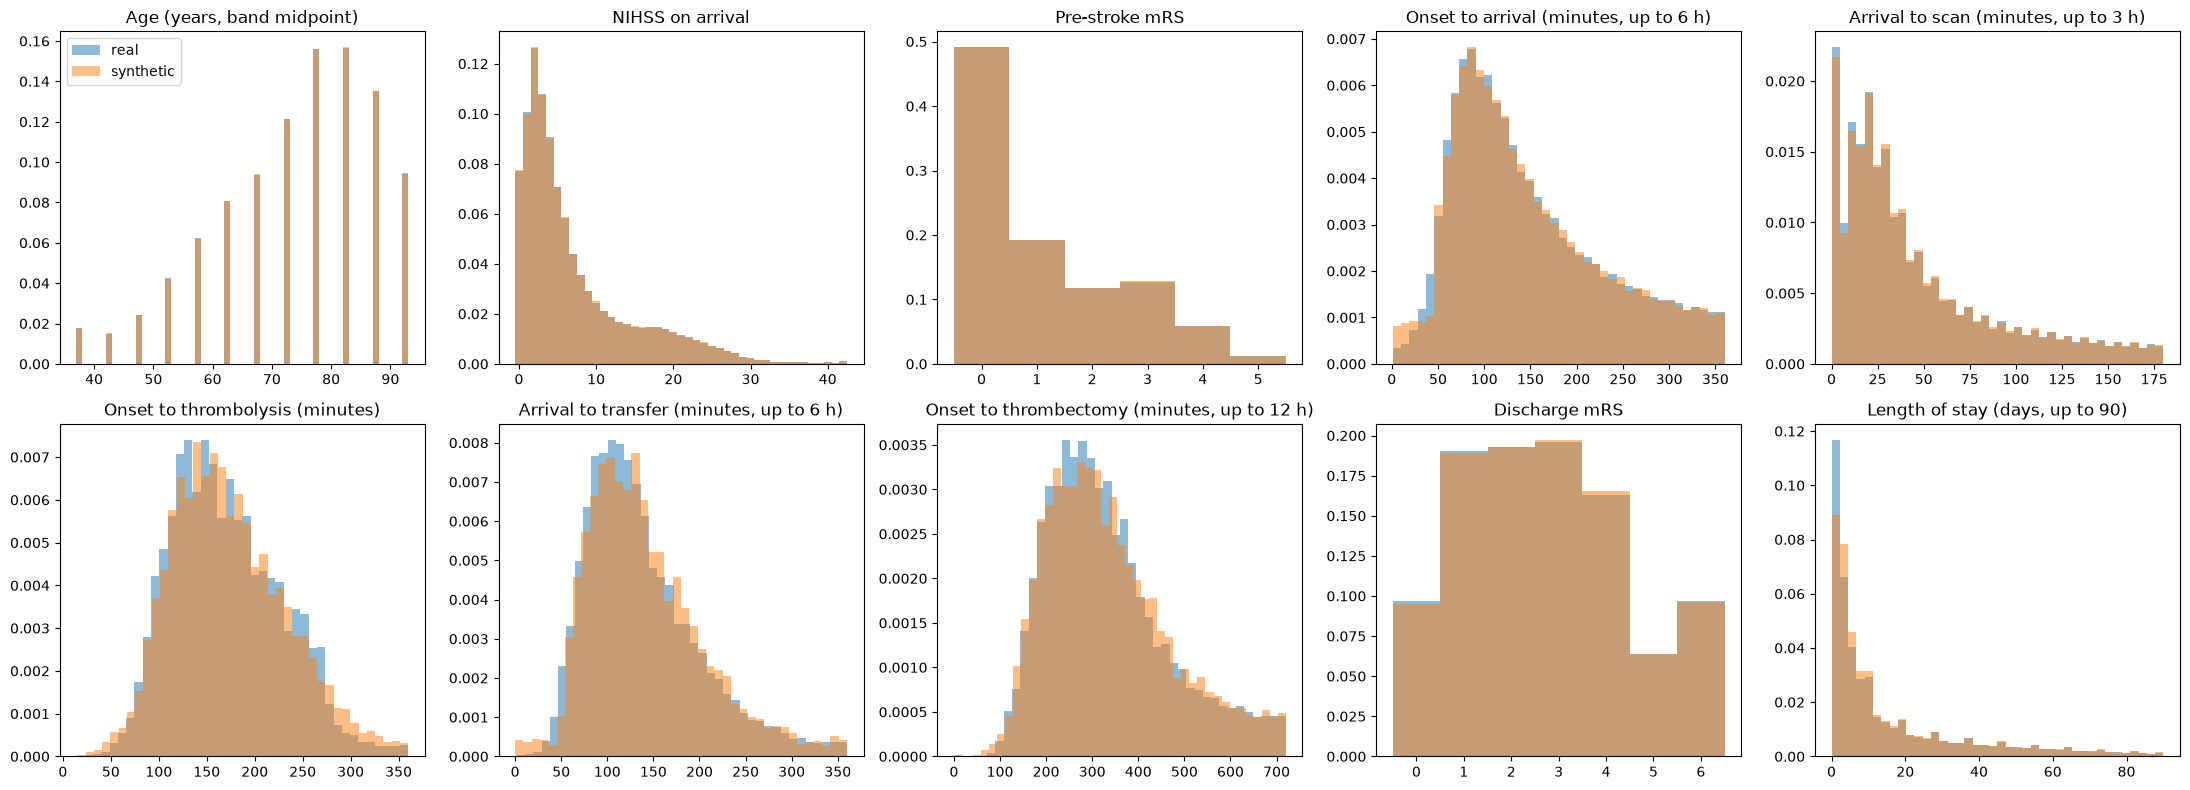

In [10]:
panels = [
    ("age", "Age (years, band midpoint)", None),
    ("stroke_severity", "NIHSS on arrival", None),
    ("prior_disability", "Pre-stroke mRS", None),
    ("onset_to_arrival_time", "Onset to arrival (minutes, up to 6 h)", 360),
    ("arrival_to_scan_time", "Arrival to scan (minutes, up to 3 h)", 180),
    ("onset_to_thrombolysis_time", "Onset to thrombolysis (minutes)", 360),
    ("transfer_time", "Arrival to transfer (minutes, up to 6 h)", 360),
    ("onset_to_thrombectomy_time", "Onset to thrombectomy (minutes, up to 12 h)", 720),
    ("discharge_disability", "Discharge mRS", None),
    ("length_of_stay", "Length of stay (days, up to 90)", 90),
]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, (col, label, upper) in zip(axes.ravel(), panels):
    for (name, d), colour in zip(DATASETS.items(), ["#1f77b4", "#ff7f0e"]):
        v = d[col].dropna()
        if upper is not None:
            v = v[(v >= 0) & (v <= upper)]
        bins = np.arange(v.min(), v.max() + 2) - 0.5 if v.nunique() < 50 else 40
        ax.hist(v, bins=bins, density=True, alpha=0.5, color=colour, label=name)
    ax.set_title(label)
axes.ravel()[0].legend()
fig.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/synthetic_vs_real_distributions.png", dpi=150)
plt.show()

**Results.** The histograms overlap closely for every field shown. Times are smoother in the synthetic data, because values are drawn uniformly within each quantile bin.

### 6.2 Correlations between fields

Spearman (rank) correlations between all numeric fields, treatment indicators and good outcome, in each data set, and their difference. Rank correlation is used because Pearson correlations between treatment times are dominated by a few extreme real times, which are deliberately not reproduced.

Largest absolute difference in pairwise correlation: 0.076
Mean absolute difference: 0.009


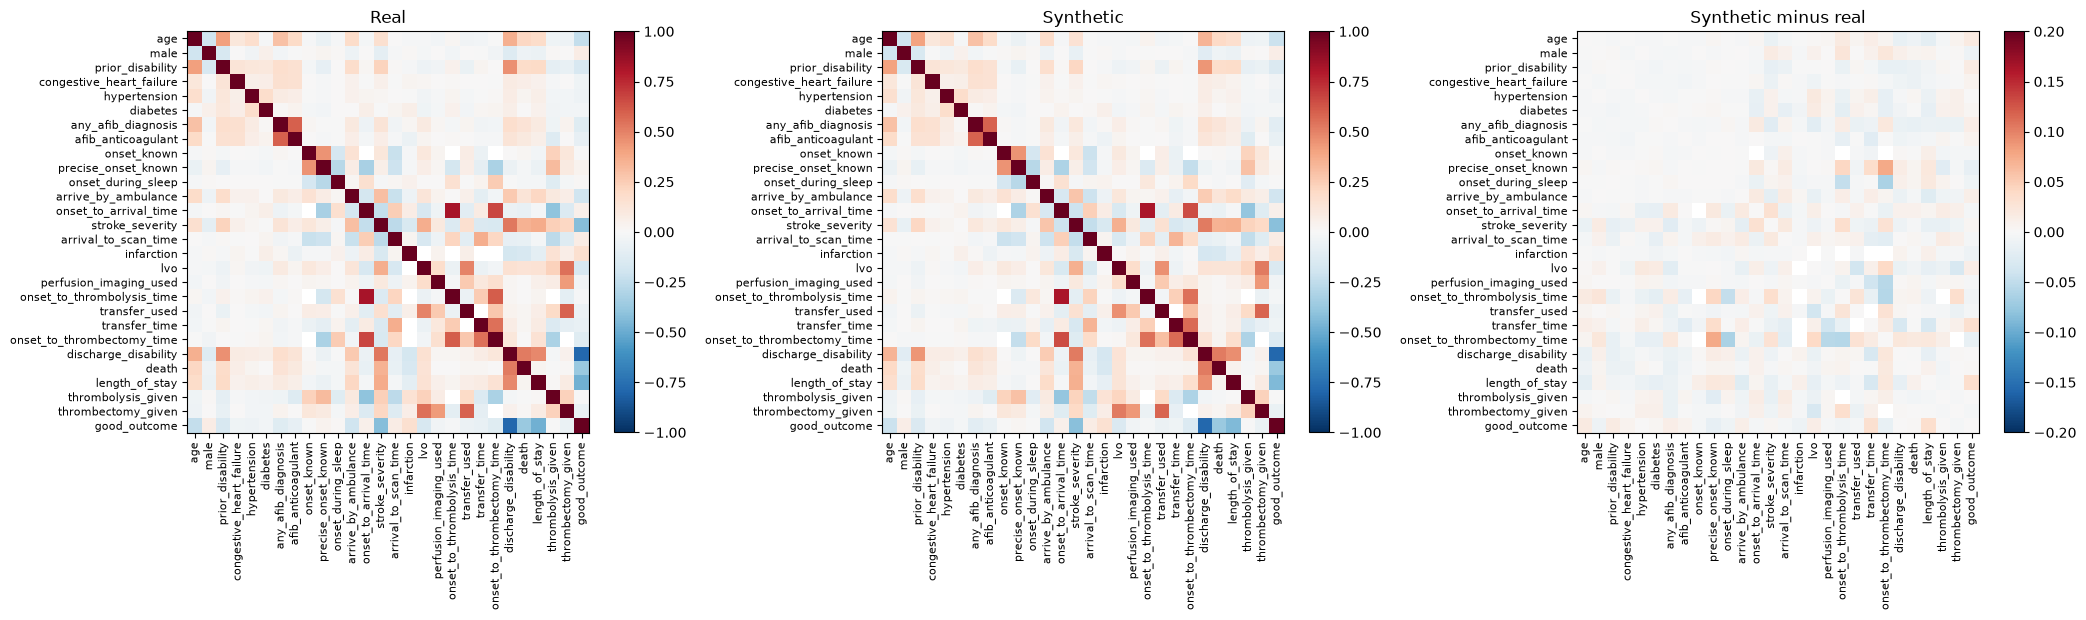

In [11]:
# Spearman (rank) correlation: not dominated by the few extreme times, which are deliberately not reproduced
corr = {name: numeric_view(d).corr(method="spearman") for name, d in DATASETS.items()}
corr_diff = corr["synthetic"] - corr["real"]
off_diagonal = corr_diff.where(~np.eye(len(corr_diff), dtype=bool)).abs()
print(f"Largest absolute difference in pairwise correlation: {off_diagonal.max().max():.3f}")
print(f"Mean absolute difference: {off_diagonal.stack().mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (title, m, vmax) in zip(axes, [("Real", corr["real"], 1), ("Synthetic", corr["synthetic"], 1),
                                       ("Synthetic minus real", corr_diff, 0.2)]):
    im = ax.imshow(m, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(len(m)), m.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(m)), m.index, fontsize=8)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/synthetic_vs_real_correlations.png", dpi=150)
plt.show()

**Results.** The largest difference in rank correlation between any two fields is 0.076, and the mean absolute difference is 0.009, so the pairwise relationships between the fields, including those with treatment and outcome, are reproduced.

### 6.3 Relationship of outcome to features

A logistic regression of good outcome on standardised features and treatment indicators is fitted separately to each data set. Similar coefficients mean the synthetic outcome depends on the features in the same way as the real outcome.

,real,synthetic,difference
prior_disability,0.147,0.149,0.001
stroke_severity,-1.062,-1.049,0.012
age,-0.424,-0.393,0.031
male,0.031,0.026,-0.005
congestive_heart_failure,-0.008,-0.010,-0.002
hypertension,-0.026,-0.024,0.002
diabetes,-0.094,-0.069,0.025
afib_anticoagulant,-0.020,-0.016,0.004
any_afib_diagnosis,-0.025,-0.023,0.002
onset_known,0.087,0.068,-0.019


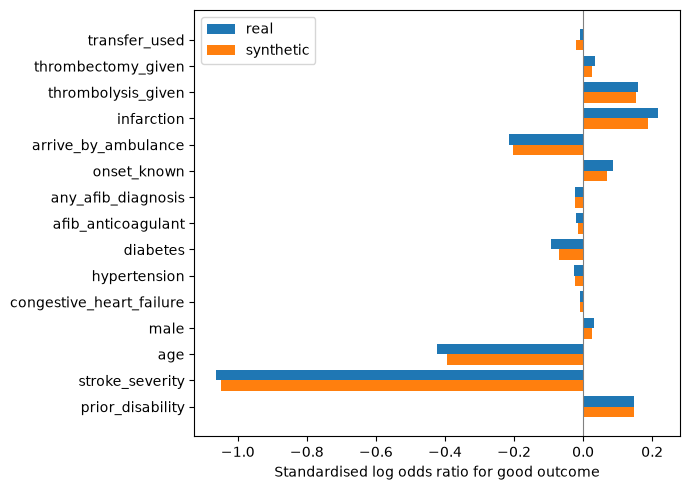

In [12]:
OUTCOME_PREDICTORS = ["prior_disability", "stroke_severity", "age", "male", "congestive_heart_failure",
                      "hypertension", "diabetes", "afib_anticoagulant", "any_afib_diagnosis",
                      "onset_known", "arrive_by_ambulance", "infarction",
                      "thrombolysis_given", "thrombectomy_given", "transfer_used"]


def outcome_coefficients(d):
    """Standardised logistic regression coefficients for good outcome (records with outcome and NIHSS)."""
    v = numeric_view(d).dropna(subset=["good_outcome", "stroke_severity", "male", "arrive_by_ambulance"])
    X = StandardScaler().fit_transform(v[OUTCOME_PREDICTORS])
    model = LogisticRegression(max_iter=1000).fit(X, v["good_outcome"])
    return pd.Series(model.coef_[0], index=OUTCOME_PREDICTORS)


coefficients = pd.DataFrame({name: outcome_coefficients(d) for name, d in DATASETS.items()})
coefficients["difference"] = coefficients["synthetic"] - coefficients["real"]
display(coefficients.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
y_pos = np.arange(len(coefficients))
ax.barh(y_pos + 0.2, coefficients["real"], height=0.4, label="real")
ax.barh(y_pos - 0.2, coefficients["synthetic"], height=0.4, label="synthetic")
ax.set_yticks(y_pos, coefficients.index)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Standardised log odds ratio for good outcome")
ax.legend()
fig.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/synthetic_vs_real_outcome_model.png", dpi=150)
plt.show()

**Results.** Every coefficient is within 0.031 of the real one. Stroke severity has by far the strongest association with good outcome in both data sets (−1.062 real, −1.049 synthetic), followed by age (−0.424, −0.393), stroke type (+0.217, +0.187), arrival by ambulance (−0.216, −0.202), thrombolysis (+0.158, +0.153) and pre-stroke mRS (+0.147, +0.149; positive because a discharge mRS no worse than before the stroke counts as good).

### 6.4 Outcome by severity, treatment and time to treatment

Good-outcome rates by NIHSS band and treatment received, and by onset-to-treatment time for thrombolysis only and thrombectomy only. These show whether the treatment–outcome and time–outcome relationships, which the S-learner estimates, are reproduced.

In [13]:
def outcome_table(d):
    """Good-outcome rate (%) by NIHSS band and treatment received, and by time to treatment."""
    v = d.assign(good=good_outcome(d)).dropna(subset=["good"])
    treatment = np.select([v["onset_to_thrombolysis_time"].notna() & v["onset_to_thrombectomy_time"].notna(),
                           v["onset_to_thrombolysis_time"].notna(), v["onset_to_thrombectomy_time"].notna()],
                          ["both", "IVT only", "MT only"], "neither")
    nihss = pd.cut(v["stroke_severity"], [-1, 5, 10, 15, 20, 42], labels=["0-5", "6-10", "11-15", "16-20", ">20"])
    by_treatment = (100 * v.groupby([nihss, treatment], observed=True)["good"].mean()).unstack()
    ivt_time = pd.cut(v["onset_to_thrombolysis_time"], [0, 90, 150, 210, 270, 360, np.inf])
    mt_time = pd.cut(v["onset_to_thrombectomy_time"], [0, 180, 270, 360, 480, 720, np.inf])
    ivt_only = treatment == "IVT only"
    mt_only = treatment == "MT only"
    by_ivt_time = 100 * v[ivt_only].groupby(ivt_time[ivt_only], observed=True)["good"].mean()
    by_mt_time = 100 * v[mt_only].groupby(mt_time[mt_only], observed=True)["good"].mean()
    return by_treatment, by_ivt_time, by_mt_time


tables = {name: outcome_table(d) for name, d in DATASETS.items()}
print("Good outcome (%) by NIHSS band (rows) and treatment received (columns)")
display(pd.concat({name: t[0] for name, t in tables.items()}, axis=1).round(1))
print("Good outcome (%) after thrombolysis only, by onset-to-thrombolysis time (minutes)")
display(pd.DataFrame({name: t[1] for name, t in tables.items()}).round(1))
print("Good outcome (%) after thrombectomy only, by onset-to-thrombectomy time (minutes)")
display(pd.DataFrame({name: t[2] for name, t in tables.items()}).round(1))

Good outcome (%) by NIHSS band (rows) and treatment received (columns)


real                       synthetic                      
                IVT only MT only  both neither  IVT only MT only  both neither
stroke_severity                                                               
0-5                 77.2    58.5  64.0    71.7      75.3    56.3  58.5    71.6
6-10                63.1    50.1  61.9    44.5      62.4    46.2  59.6    45.3
11-15               46.7    38.3  49.4    27.6      47.8    37.0  46.7    27.8
16-20               31.6    27.8  36.1    16.4      32.4    25.2  34.6    16.1
>20                 21.5    18.2  25.2    10.2      24.5    16.9  23.9    10.3

Good outcome (%) after thrombolysis only, by onset-to-thrombolysis time (minutes)


,real,synthetic
onset_to_thrombolysis_time,,
"(0.0, 90.0]",62.8,60.2
"(90.0, 150.0]",58.0,58.8
"(150.0, 210.0]",57.7,58.1
"(210.0, 270.0]",57.6,57.0
"(270.0, 360.0]",57.8,58.0
"(360.0, inf]",54.0,53.0


Good outcome (%) after thrombectomy only, by onset-to-thrombectomy time (minutes)


,real,synthetic
onset_to_thrombectomy_time,,
"(0.0, 180.0]",44.5,43.1
"(180.0, 270.0]",37.9,38.8
"(270.0, 360.0]",35.4,31.9
"(360.0, 480.0]",34.5,32.0
"(480.0, 720.0]",33.6,31.8
"(720.0, inf]",28.7,25.6


**Results.**

* **By NIHSS band and treatment:** good-outcome rates fall with severity in every treatment group, as in the real data. For untreated patients rates agree within 0.8 percentage points in every band, and for thrombolysis only within 3.0. For both treatments they agree within 2.7 points at NIHSS 6 and above (58.5% vs 64.0% at NIHSS 0–5), and for thrombectomy only within 3.9 points in every band.
* **By time to thrombolysis:** good outcome falls with later treatment in both, from 62.8% at 0–90 minutes to 54.0% after 6 hours in the real data, and from 60.2% to 53.0% in the synthetic data.
* **By time to thrombectomy:** good outcome falls with later treatment in both, from 44.5% within 3 hours to 28.7% after 12 hours in the real data, and from 43.1% to 25.6% in the synthetic data; the intermediate bands are within 3.5 points.

**Discussion.** The relationships of outcome to severity, treatment and time to treatment are reproduced, including the decline in benefit with time to thrombectomy. This depends on modelling the outcomes separately for each treatment, with the total onset-to-treatment times as predictors.

### 6.5 Machine learning utility

A gradient-boosted model predicting good outcome is trained on synthetic data and tested on held-out real data ("train synthetic, test real"), and compared with the same model trained and tested on real data. Similar ROC AUCs mean a model learned from the synthetic data behaves like one learned from the real data. (Stroke team and ethnicity are not used, because team names differ between the data sets.)

In [14]:
ML_FEATURES = ["prior_disability", "stroke_severity", "age", "congestive_heart_failure", "hypertension",
               "diabetes", "afib_anticoagulant", "any_afib_diagnosis", "infarction",
               "onset_to_thrombolysis_time", "onset_to_thrombectomy_time"]


def with_outcome(d):
    v = d.assign(good=good_outcome(d)).dropna(subset=["good"])
    return v[ML_FEATURES], v["good"].astype(int)


X_real, y_real = with_outcome(real)
X_train, X_test, y_train, y_test = train_test_split(X_real, y_real, test_size=0.3, random_state=SEED,
                                                    stratify=y_real)
X_syn, y_syn = with_outcome(synthetic)
X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(X_syn, y_syn, test_size=0.3,
                                                                    random_state=SEED, stratify=y_syn)


def auc(X_fit, y_fit, X_eval, y_eval):
    model = HistGradientBoostingClassifier(random_state=SEED).fit(X_fit, y_fit)
    return roc_auc_score(y_eval, model.predict_proba(X_eval)[:, 1])


pd.DataFrame({"ROC AUC": {
    "Train real, test real": auc(X_train, y_train, X_test, y_test),
    "Train synthetic, test real": auc(X_syn_train, y_syn_train, X_test, y_test),
    "Train synthetic, test synthetic": auc(X_syn_train, y_syn_train, X_syn_test, y_syn_test),
}}).round(3)

,ROC AUC
"Train real, test real",0.797
"Train synthetic, test real",0.797
"Train synthetic, test synthetic",0.792


**Results.** A model trained on synthetic data and tested on real data has ROC AUC 0.797, the same as a model trained and tested on real data (0.797). Trained and tested on synthetic data, the AUC is 0.792.

**Discussion.** A model learned from the synthetic data captures the predictive relationships in the real data as well as one learned from the real data, so the synthetic data is suitable for demonstrating machine learning code.

### 6.6 The S-learner's cohort

The S-learner's selection rules (discharge mRS recorded, infarction, arrival within 6 hours, no perfusion imaging, NIHSS > 5 or LVO, teams with at least 10 thrombectomies, plausible treatment times) and its treatment groups (early = thrombolysis within 270 minutes or thrombectomy before 270 minutes) are applied to both data sets. The table shows the number of patients and the good-outcome rate in each treatment group.

In [15]:
CUTOFF = 270


def s_learner_cohort(d):
    """The S-learner's cohort selection and treatment groups."""
    d = d[d["discharge_disability"].notna() & (d["infarction"] == 1) & (d["onset_to_arrival_time"] < 360)
          & (d["perfusion_imaging_used"] == 0) & ((d["stroke_severity"] > 5) | (d["lvo"] == 1))]
    mt_count = d.groupby("stroke_team")["onset_to_thrombectomy_time"].count()
    d = d[d["stroke_team"].isin(mt_count.index[mt_count >= 10])]
    ivt, mt = d["onset_to_thrombolysis_time"], d["onset_to_thrombectomy_time"]
    d = d[~(ivt.notna() & mt.notna() & (ivt > mt)) & (mt.isna() | (mt < 720)) & (ivt.isna() | (ivt < 360))]
    ivt, mt = d["onset_to_thrombolysis_time"], d["onset_to_thrombectomy_time"]
    group = pd.Series("neither", index=d.index)
    group[(ivt <= CUTOFF) & mt.isna()] = "early_thrombolysis_only"
    group[(ivt > CUTOFF) & mt.isna()] = "late_thrombolysis_only"
    group[ivt.isna() & (mt < CUTOFF)] = "early_thrombectomy_only"
    group[ivt.isna() & (mt >= CUTOFF)] = "late_thrombectomy_only"
    group[(ivt <= CUTOFF) & (mt < CUTOFF)] = "early_both"
    group[(ivt <= CUTOFF) & (mt >= CUTOFF)] = "early_thrombolysis_late_thrombectomy"
    group[(ivt > CUTOFF) & (mt > CUTOFF)] = "late_both"
    return d.assign(treatment_group=group, good=good_outcome(d))


GROUPS = ["neither", "early_thrombolysis_only", "late_thrombolysis_only", "early_thrombectomy_only",
          "late_thrombectomy_only", "early_both", "early_thrombolysis_late_thrombectomy", "late_both"]
cohorts = {name: s_learner_cohort(d) for name, d in DATASETS.items()}
print({name: f"{len(c):,} patients, {c['stroke_team'].nunique()} teams" for name, c in cohorts.items()})
pd.concat({name: pd.DataFrame({"n": c["treatment_group"].value_counts(),
                               "good outcome %": 100 * c.groupby("treatment_group")["good"].mean()})
           for name, c in cohorts.items()}, axis=1).reindex(GROUPS).round(1)

{'real': '74,678 patients, 109 teams', 'synthetic': '72,962 patients, 107 teams'}


real                synthetic  \
                                          n good outcome %         n   
treatment_group                                                        
neither                               37647           37.7     38507   
early_thrombolysis_only               27695           49.0     25367   
late_thrombolysis_only                 1189           47.2      1749   
early_thrombectomy_only                1107           38.8       969   
late_thrombectomy_only                 1876           33.6      1856   
early_both                             2309           46.4      1923   
early_thrombolysis_late_thrombectomy   2714           37.2      2404   
late_both                               141           44.0       187   

                                                     
                                     good outcome %  
treatment_group                                      
neither                                        36.5  
early_thrombolysis_only                        50.0  
late_thrombolysis_only                         48.3  
early_thrombectomy_only                        38.7  
late_thrombectomy_only                         30.2  
early_both                                     44.8  
early_thrombolysis_late_thrombectomy           35.6  
late_both                                      29.9

**Results.** The S-learner's selection gives 72,962 synthetic patients from 107 teams, compared with 74,678 real patients from 109 teams.

* Treatment group sizes are similar for most groups, but the synthetic cohort has fewer early thrombolysis only (25,367 vs 27,695) and early both (1,923 vs 2,309), and more untreated patients (38,507 vs 37,647) and late thrombolysis only (1,749 vs 1,189).
* Good-outcome rates agree within 1.6 percentage points for untreated patients (36.5% vs 37.7%), early thrombolysis only (50.0% vs 49.0%), late thrombolysis only (48.3% vs 47.2%), early thrombectomy only (38.7% vs 38.8%), early both (44.8% vs 46.4%) and early thrombolysis with late thrombectomy (35.6% vs 37.2%). Late thrombectomy only is 3.4 points lower (30.2% vs 33.6%), and late both, the smallest group, is lower (29.9% vs 44.0%).

**Discussion.** The S-learner's cohort selection and treatment groups work on the synthetic data and give a cohort of similar size and make-up, with good-outcome rates close to the real ones in every group except the very small late-both group.

## 7. Privacy check

Synthetic records should not reproduce real patients. The real data is split at random into a reference half and a held-out half. Synthetic records are compared with the reference half, and so are the real patients in the held-out half, who were never seen by the comparison: their match rate shows how often matches occur by chance, because many patients share common profiles.

Matching is checked on all 27 fields and on the 13 fields used by the S-learner, each with exact values and with times grouped into 30-minute bins (and length of stay into 7-day bins). With all 27 fields almost every record is unique, so the smaller field set gives the more informative test. A synthetic match rate no higher than the held-out rate, including for reference records that are unique, shows that the generator has not memorised individual patients.

In [16]:
# Real data with stroke teams given the same anonymous names as in the synthetic data
real_anon = real.assign(stroke_team=real["stroke_team"].map(lambda t: f"synth{team_code[t] + 1:03d}"))
TIME_FIELDS = ["onset_to_arrival_time", "arrival_to_scan_time", "onset_to_thrombolysis_time",
               "transfer_time", "onset_to_thrombectomy_time"]   # minutes


def record_keys(d, fields, coarse=False):
    """One hash per record over the given fields; if coarse, times are grouped into 30-minute bins
    and length of stay into 7-day bins."""
    d = d[fields].copy()
    if coarse:
        times = [c for c in TIME_FIELDS if c in fields]
        d[times] = d[times] // 30
        if "length_of_stay" in fields:
            d["length_of_stay"] = d["length_of_stay"] // 7
    return pd.util.hash_pandas_object(d.astype(str), index=False)


# The real data is split at random into a reference half (A) and a held-out half (B). Synthetic records
# are compared with half A, and so are the real patients in half B: real patients that were never seen
# show how often matches occur by chance, because many patients share common profiles.
half_a = rng.random(len(real_anon)) < 0.5
results = {}
for fields_label, fields in [("all 27 fields", FIELDS), ("13 S-learner fields", S_LEARNER_FIELDS)]:
    for time_label, coarse in [("exact", False), ("binned times", True)]:
        real_keys = record_keys(real_anon, fields, coarse)
        reference = real_keys[half_a]
        counts = reference.value_counts()
        unique_reference = set(counts.index[counts == 1])
        for name, keys in [("synthetic", record_keys(synthetic, fields, coarse)),
                           ("held-out real (baseline)", real_keys[~half_a])]:
            results[(fields_label, time_label, name)] = {
                "match a reference record (%)": 100 * keys.isin(set(reference)).mean(),
                "match a unique reference record (%)": 100 * keys.isin(unique_reference).mean()}
pd.DataFrame(results).T.round(2)

match a reference record (%)  \
all 27 fields       exact        synthetic                                         0.00   
                                 held-out real (baseline)                          0.00   
                    binned times synthetic                                         0.07   
                                 held-out real (baseline)                          0.07   
13 S-learner fields exact        synthetic                                        16.11   
                                 held-out real (baseline)                         16.31   
                    binned times synthetic                                        16.16   
                                 held-out real (baseline)                         16.36   

                                                           match a unique reference record (%)  
all 27 fields       exact        synthetic                                                0.00  
                                 held-out real (baseline)                                 0.00  
                    binned times synthetic                                                0.07  
                                 held-out real (baseline)                                 0.07  
13 S-learner fields exact        synthetic                                                9.86  
                                 held-out real (baseline)                                 9.94  
                    binned times synthetic                                                9.91  
                                 held-out real (baseline)                                 9.99

**Results.**

| Fields compared | Times | Synthetic: match any | Baseline: match any | Synthetic: match unique | Baseline: match unique |
|---|---|---|---|---|---|
| All 27 fields | exact | 0.00% | 0.00% | 0.00% | 0.00% |
| All 27 fields | binned | 0.07% | 0.07% | 0.07% | 0.07% |
| 13 S-learner fields | exact | 16.11% | 16.31% | 9.86% | 9.94% |
| 13 S-learner fields | binned | 16.16% | 16.36% | 9.91% | 9.99% |

**Discussion.** With all 27 fields, almost no records (real or synthetic) match, because nearly every record is unique. On the S-learner's 13 fields, about 16% of records match a reference record, but synthetic records do so slightly *less* often than real patients who were never seen by the comparison, including for real records that are unique. The matches are what would be expected from patients sharing common profiles (for example, untreated patients with unknown onset), so there is no evidence that the generator has memorised individual patients, even with the smaller minimum leaf size of 100. This is a simple record-matching check, not a formal privacy guarantee.

## 8. Save the synthetic data

The synthetic data is saved as a CSV file with the same columns as the real cleaned data.

In [17]:
synthetic.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {len(synthetic):,} synthetic records to {OUTPUT_PATH}")

Saved 452,863 synthetic records to ./synthetic_data/synthetic_cleaned_data.csv


**Results.** 452,863 synthetic records saved to `data/sam3/synthetic_data/synthetic_cleaned_data.csv` (with the three figures above in the same folder).

## 9. Using the synthetic data, and conclusions

### Using the synthetic data with the S-learner notebook

Set `DATA_PATH = "../data/sam3/synthetic_data/synthetic_cleaned_data.csv"` in the S-learner notebook's settings. Every field the S-learner uses is included, except year of admission, which appears only in the extended descriptive statistics table (that cell will not run, and can be skipped). Everything else, including the cohort selection, patient flow diagram, tuning, cross-validation, counterfactual predictions, sensitivity analyses and the observed outcomes table (death and length of stay), uses only fields in the synthetic data.

### Conclusions

* **Format.** The synthetic data has the same 27 columns, names, order and types as the real cleaned data, in the order of the patient pathway, for all 452,863 records, with anonymous stroke team names (synth001 to synth116).
* **Coherent pathway.** No synthetic record breaks the pathway rules (onset, arrival, scan, thrombolysis, transfer, thrombectomy, death).
* **Fidelity.** The distribution of every field is reproduced (means and SDs within 0.01 for patient characteristics; median times within 8 minutes), as are the relationships between fields (rank correlations within 0.08; outcome-model coefficients within 0.031).
* **Outcome related to features.** Good outcome depends on stroke severity, age, pre-stroke disability, arrival by ambulance, treatment and time to treatment as in the real data, including the decline in benefit with time to thrombolysis and to thrombectomy, and a model trained on synthetic data predicts real outcomes as well as one trained on real data (ROC AUC 0.797).
* **The S-learner's cohort** can be selected from the synthetic data and is of similar size and make-up to the real cohort, with good-outcome rates within 1.6 percentage points in most treatment groups.
* **Privacy.** Synthetic records match real records no more often than unseen real patients do.

### Limitations

* **Not for inference.** The synthetic data is for demonstrating and testing code. Effect estimates from it will be similar to, but not the same as, the real ones: thrombolysis is slightly less common (11.4% vs 12.0% of records), the S-learner cohort has fewer early-thrombolysis patients, and good-outcome rates in the small late-thrombectomy groups are lower than in the real data.
* **Relationships are as good as the generating models.** Each field depends on the earlier ones through a regularised model (at least 100 patients per leaf), so strong but rare patterns, and interactions in small groups (such as thrombectomy in mild strokes, or late thrombolysis plus late thrombectomy), are smoothed.
* **Tails.** Times and lengths of stay above the 99.9th percentile are not reproduced, and values within each bin are uniform, so the long tails differ.
* **Death** is missing whenever discharge mRS is missing (in the real data it is sometimes recorded as 0).
* **Privacy.** The safeguards (anonymous team names, at least 100 patients per model leaf, no extreme values, a record-matching check) reduce disclosure risk but are not a formal privacy guarantee such as differential privacy. Approval should be sought before the synthetic data is shared outside the project.